In [210]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path 
import sys
import re,ast
import joblib
import json
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity

In [60]:
file_path = "data/raw/02_CortexHR_AI_ML_Dataset.xlsx"

In [61]:
training = pd.read_excel(file_path, sheet_name="chatbot_nlu_training")
testing = pd.read_excel(file_path, sheet_name="chatbot_test_set")
faq = pd.read_excel(file_path, sheet_name="hr_faq")
responses = pd.read_excel(file_path, sheet_name="chatbot_responses")

In [62]:
training.shape

(858, 4)

In [63]:
training.columns.tolist()

['example_id', 'text', 'intent', 'entities']

In [64]:
training.head(20)

,example_id,text,intent,entities
0,NLU-0001,I want to know who is in my team,team_members,NaN
1,NLU-0002,I want to know show the payslip of Karthik Iye...,salary_of_other,"[{""entity"": ""person_name"", ""value"": ""Karthik I..."
2,NLU-0003,"can you tell me that helped, thank you pls",thanks,NaN
3,NLU-0004,"hey, leave balance please",leave_balance,NaN
4,NLU-0005,screen candidates for Support Executive,resume_score_request,"[{""entity"": ""role"", ""value"": ""Support Executiv..."
5,NLU-0006,I want to know when is the next public holiday...,holiday_list,NaN
6,NLU-0007,quick question: suggest a slaary band for Acco...,salary_band_query,"[{""entity"": ""role"", ""value"": ""Accountant"", ""no..."
7,NLU-0008,can you tell me what is your name ?,chitchat,NaN
8,NLU-0009,I want to know what is the expense claim proce...,reimbursement_policy,NaN
9,NLU-0010,can you tell me what is the notice period ?,notice_period_policy,NaN


In [65]:
testing.shape

(132, 4)

In [66]:
testing.columns.tolist()

['test_id', 'text', 'expected_intent', 'expected_entities']

In [67]:
testing.head()

,test_id,text,expected_intent,expected_entities
0,TST-001,yo,greet,NaN
1,TST-002,heya,greet,NaN
2,TST-003,hello bot,greet,NaN
3,TST-004,hi there assistant,greet,NaN
4,TST-005,catch you later,goodbye,NaN


In [68]:
faq.shape

(30, 5)

In [69]:
faq.columns.tolist()

['faq_id', 'question', 'answer', 'category', 'policy_source']

In [70]:
faq.head()

,faq_id,question,answer,category,policy_source
0,FAQ-01,How many casual leaves do I get?,"12 days per financial year, prorated for joiners.",Leave,Zenith Nova HR Policy Handbook v3.2 (fictional...
1,FAQ-02,How many sick leaves do I get?,12 days per financial year. A medical certific...,Leave,Zenith Nova HR Policy Handbook v3.2 (fictional...
2,FAQ-03,How does earned leave work?,It accrues at 1.25 days per month and up to 30...,Leave,Zenith Nova HR Policy Handbook v3.2 (fictional...
3,FAQ-04,Is leave without pay allowed?,"Yes, when other balances are exhausted. It is ...",Leave,Zenith Nova HR Policy Handbook v3.2 (fictional...
4,FAQ-05,What is the maternity leave policy?,26 weeks of paid maternity leave as per statute.,Leave,Zenith Nova HR Policy Handbook v3.2 (fictional...


In [71]:
responses.shape

(33, 7)

In [72]:
responses.columns.tolist()

['intent',
 'response_template',
 'requires_login',
 'allowed_roles',
 'backend_or_service_call',
 'on_failure',
 'policy_note']

In [73]:
responses.head()

,intent,response_template,requires_login,allowed_roles,backend_or_service_call,on_failure,policy_note
0,greet,Hello! I am the Zenith Nova HR assistant. Ask ...,N,ALL,NaN,NaN,NaN
1,goodbye,Goodbye! Message me anytime.,N,ALL,NaN,NaN,NaN
2,thanks,You are welcome!,N,ALL,NaN,NaN,NaN
3,hr_policy_leave,You get 12 casual leave and 12 sick leave days...,N,ALL,faq:hr_policy_leave,NaN,NaN
4,working_hours,"Office hours are 9:00 to 18:00, Monday to Frid...",N,ALL,faq:working_hours,NaN,NaN


In [74]:
# investing the training data

In [75]:
intent_counts = training["intent"].value_counts()

In [76]:
training["intent"].nunique()

33

In [77]:
intent_counts.to_frame(name="message_count")

,message_count
intent,
team_members,26
salary_of_other,26
thanks,26
leave_balance,26
resume_score_request,26
holiday_list,26
salary_band_query,26
chitchat,26
reimbursement_policy,26


In [78]:
training["text"].isna().sum()

np.int64(0)

In [79]:
training["intent"].isna().sum()

np.int64(0)

In [80]:
training["text"].duplicated().sum()

np.int64(0)

In [81]:
print("Messages with leading/trailing spaces:",
      (training["text"] != training["text"].str.strip()).sum())

print("Messages containing repeated spaces:",
      training["text"].str.contains(r"\s{2,}", na=False).sum())

Messages with leading/trailing spaces: 0
Messages containing repeated spaces: 0


In [82]:
print("Number of test messages:", len(testing))
print("Number of unique expected intents:",
      testing["expected_intent"].nunique())


Number of test messages: 132
Number of unique expected intents: 33


In [83]:
testing["expected_intent"].value_counts().to_frame(name="message_count")


,message_count
expected_intent,
greet,4
goodbye,4
thanks,4
hr_policy_leave,4
working_hours,4
holiday_list,4
payslip_date,4
apply_leave_howto,4
reimbursement_policy,4


In [84]:
train_intents = set(training["intent"].dropna().unique())
test_intents = set(testing["expected_intent"].dropna().unique())

print("Intents in training:", len(train_intents))
print("Intents in test set:", len(test_intents))
print("Test intents missing from training:", sorted(test_intents - train_intents))

response_intents = set(responses["intent"].dropna().unique())

print("Unique configured response intents:", len(response_intents))
print("Training intents without response configuration:",
      sorted(train_intents - response_intents))

Intents in training: 33
Intents in test set: 33
Test intents missing from training: []
Unique configured response intents: 33
Training intents without response configuration: []


In [85]:
#clean and normalizing the chatbot message

In [86]:
typo_map = {
    "slaary": "salary",
    "levaes": "leaves",
    "levae": "leave",
    "leaevs": "leaves",
    "fowrard": "forward",
    "offcie": "office",
    "wokring": "working",
    "huors": "hours",
    "plaese": "please"
}


In [87]:
def clean_text(text):
    text = str(text).lower()

    for i,j in typo_map.items():
        text=re.sub( rf"\b{re.escape(i)}\b",j,
            text
        )
    text=re.sub(r"\s+", " ", text).strip()
    return text 

In [88]:
training["text_clean"] = training["text"].apply(clean_text)
testing["text_clean"] = testing["text"].apply(clean_text)

In [89]:
training[["text", "text_clean", "intent"]].head(20)

,text,text_clean,intent
0,I want to know who is in my team,i want to know who is in my team,team_members
1,I want to know show the payslip of Karthik Iye...,i want to know show the payslip of karthik iye...,salary_of_other
2,"can you tell me that helped, thank you pls","can you tell me that helped, thank you pls",thanks
3,"hey, leave balance please","hey, leave balance please",leave_balance
4,screen candidates for Support Executive,screen candidates for support executive,resume_score_request
5,I want to know when is the next public holiday...,i want to know when is the next public holiday...,holiday_list
6,quick question: suggest a slaary band for Acco...,quick question: suggest a salary band for acco...,salary_band_query
7,can you tell me what is your name ?,can you tell me what is your name ?,chitchat
8,I want to know what is the expense claim proce...,i want to know what is the expense claim proce...,reimbursement_policy
9,can you tell me what is the notice period ?,can you tell me what is the notice period ?,notice_period_policy


In [90]:
#TF-IDF Vectorization 

In [91]:
tfidf = TfidfVectorizer(ngram_range=(1, 2),min_df=1,sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(training["text_clean"])
X_test_tfidf = tfidf.transform(testing["text_clean"])

In [92]:
X_train_tfidf.shape

(858, 1593)

In [93]:
X_test_tfidf.shape

(132, 1593)

In [94]:
len(tfidf.vocabulary_)

1593

In [95]:
type(X_train_tfidf)

scipy.sparse._csr.csr_matrix

In [96]:
 type(X_test_tfidf)

scipy.sparse._csr.csr_matrix

In [97]:
list(tfidf.vocabulary_.keys())[:20]

['want',
 'to',
 'know',
 'who',
 'is',
 'in',
 'my',
 'team',
 'want to',
 'to know',
 'know who',
 'who is',
 'is in',
 'in my',
 'my team',
 'show',
 'the',
 'payslip',
 'of',
 'karthik']

In [98]:
# train logistic Regression Classifier 

In [99]:
y_train = training["intent"]
y_test = testing["expected_intent"]

In [100]:
log_mod=LogisticRegression(max_iter=1000,random_state=42)

log_mod.fit(X_train_tfidf, y_train)

log_mod

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [101]:
len(log_mod.classes_)

33

In [102]:
 X_train_tfidf.shape[0]

858

In [103]:
 X_train_tfidf.shape[1]

1593

In [104]:
log_mod.classes_

array(['apply_leave_howto', 'attendance_summary', 'attrition_risk_query',
       'chitchat', 'goodbye', 'greet', 'headcount_forecast', 'help',
       'holiday_list', 'hr_policy_leave', 'insurance_benefits',
       'leave_balance', 'leave_request_status', 'my_department',
       'my_manager', 'notice_period_policy', 'out_of_scope',
       'payroll_flags', 'payslip_date', 'payslip_status', 'pf_info',
       'probation_policy', 'reimbursement_policy', 'resume_score_request',
       'salary_band_query', 'salary_of_other', 'tax_declaration',
       'team_members', 'thanks', 'unusual_attendance', 'wfh_policy',
       'who_to_contact', 'working_hours'], dtype=object)

In [105]:
# evaluating the classifier because we dont know how accurately it predicts the unseen data 

In [106]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [107]:
y_pred = log_mod.predict(X_test_tfidf)

In [108]:
accuracy = accuracy_score(y_test, y_pred)

In [109]:
print(f"Test Accuracy (%): {accuracy * 100:.2f}%")


Test Accuracy (%): 75.76%


In [110]:
print(classification_report(y_test,y_pred,labels=log_mod.classes_,zero_division=0))

                      precision    recall  f1-score   support

   apply_leave_howto       1.00      1.00      1.00         4
  attendance_summary       1.00      0.75      0.86         4
attrition_risk_query       1.00      1.00      1.00         4
            chitchat       0.60      0.75      0.67         4
             goodbye       1.00      1.00      1.00         4
               greet       0.80      1.00      0.89         4
  headcount_forecast       0.75      0.75      0.75         4
                help       0.33      0.25      0.29         4
        holiday_list       0.50      0.50      0.50         4
     hr_policy_leave       0.40      0.50      0.44         4
  insurance_benefits       1.00      0.75      0.86         4
       leave_balance       0.75      0.75      0.75         4
leave_request_status       0.80      1.00      0.89         4
       my_department       1.00      0.75      0.86         4
          my_manager       0.67      1.00      0.80         4
notice_

In [111]:
cm=confusion_matrix(y_test,y_pred,labels=log_mod.classes_)

In [112]:
confusion_df = pd.DataFrame(
    cm,
    index=log_mod.classes_,
    columns=log_mod.classes_
)

In [113]:
confusion_df

,apply_leave_howto,attendance_summary,attrition_risk_query,chitchat,goodbye,greet,headcount_forecast,help,holiday_list,hr_policy_leave,...,resume_score_request,salary_band_query,salary_of_other,tax_declaration,team_members,thanks,unusual_attendance,wfh_policy,who_to_contact,working_hours
apply_leave_howto,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
attendance_summary,0,3,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
attrition_risk_query,0,0,4,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
chitchat,0,0,0,3,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
goodbye,0,0,0,0,4,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
greet,0,0,0,0,0,4,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
headcount_forecast,0,0,0,0,0,0,3,0,0,0,...,0,0,0,0,0,0,0,1,0,0
help,0,0,0,1,0,0,0,1,1,0,...,0,0,1,0,0,0,0,0,0,0
holiday_list,0,0,0,0,0,0,0,0,2,1,...,0,0,0,0,0,0,0,1,0,0
hr_policy_leave,0,0,0,0,0,0,0,0,0,2,...,0,0,0,0,0,0,0,0,0,1


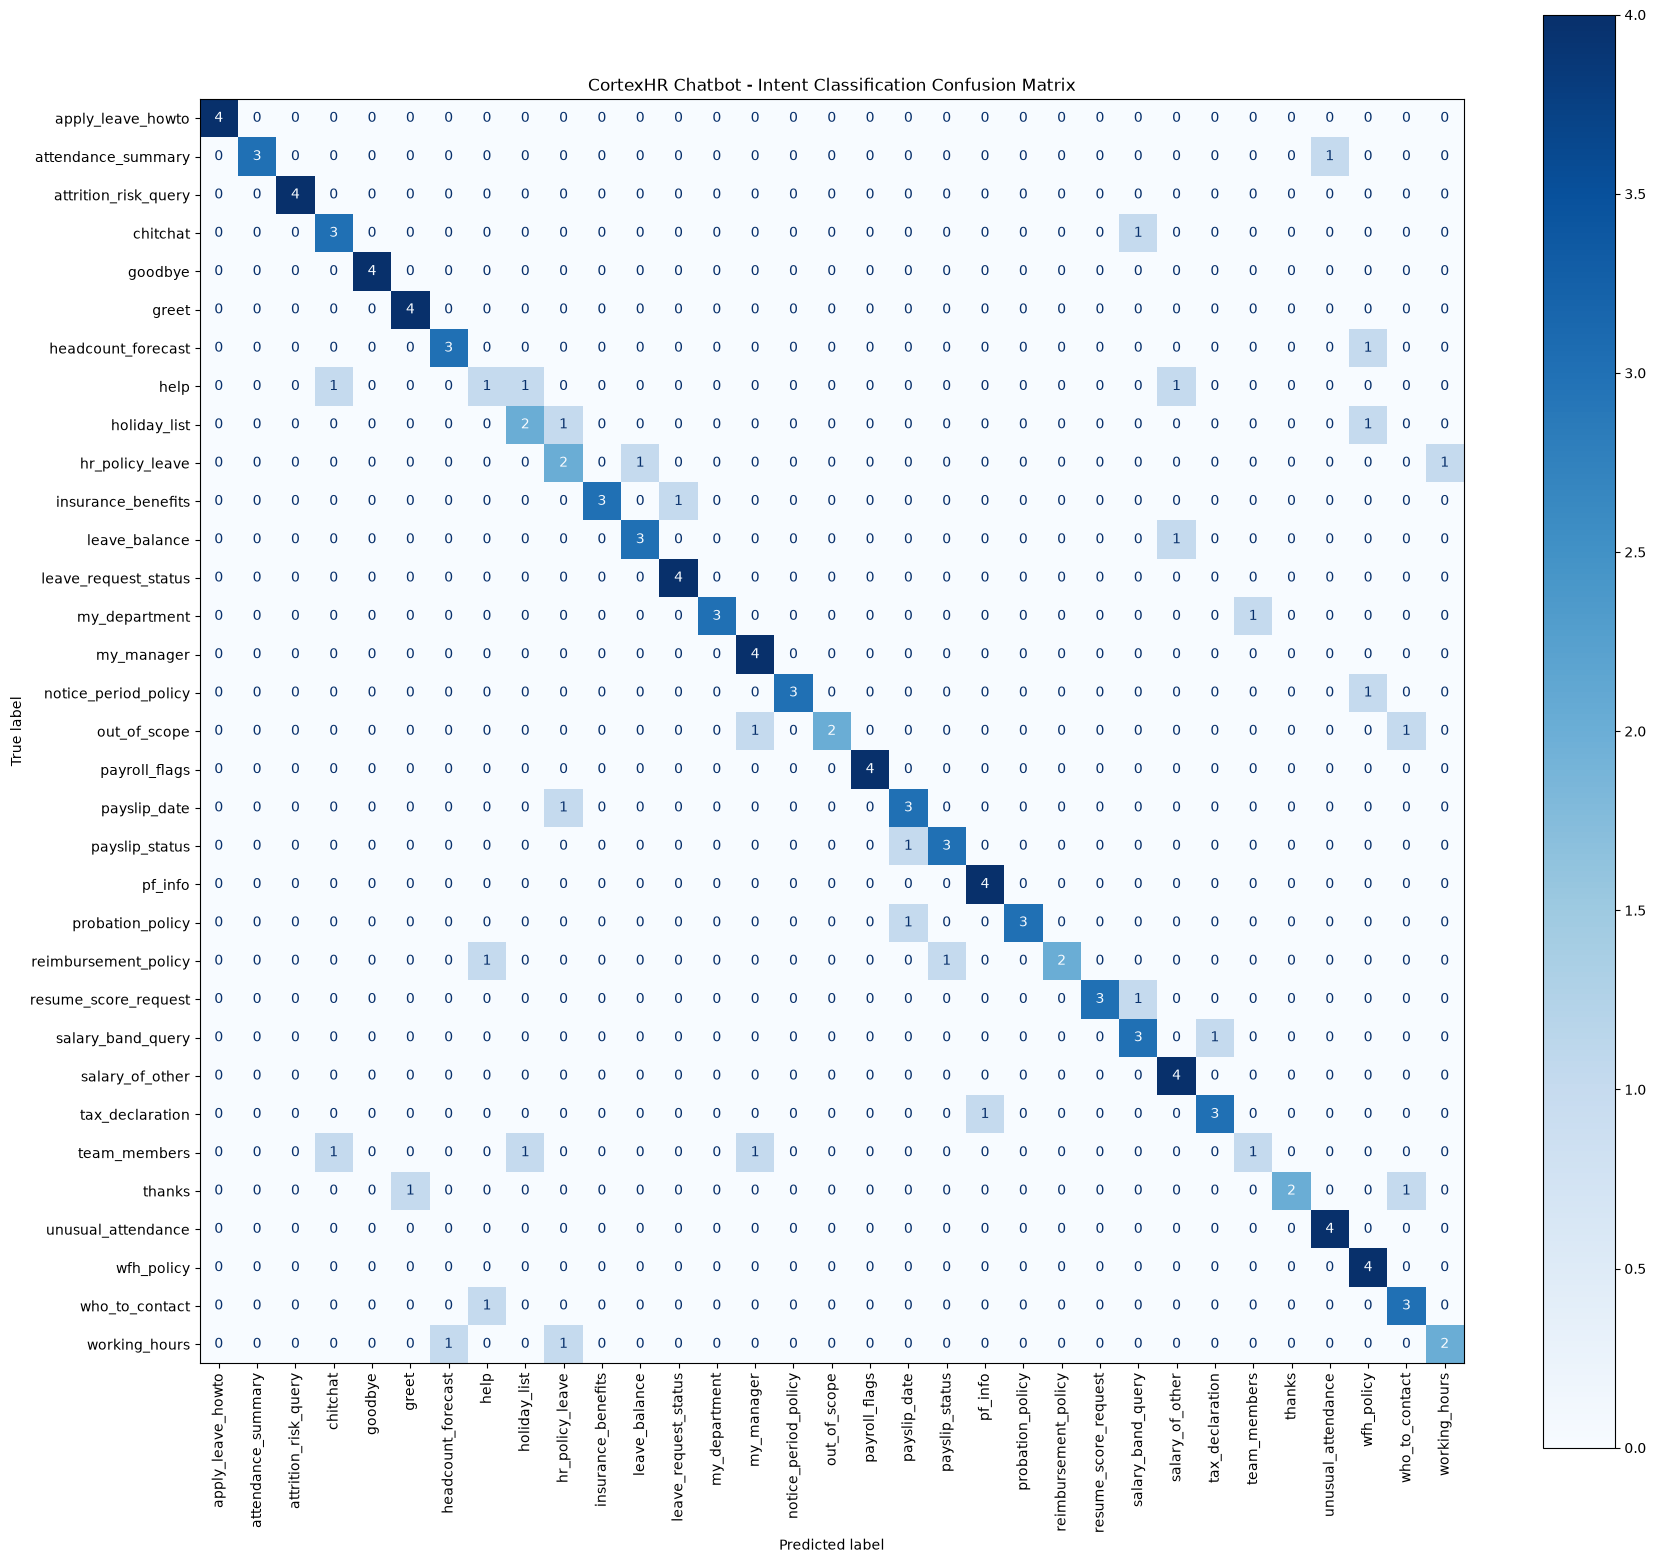

In [114]:
fig, ax = plt.subplots(figsize=(18, 16))
cm_plot = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=log_mod.classes_
)
cm_plot.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=True
)

plt.title("CortexHR Chatbot - Intent Classification Confusion Matrix")
plt.tight_layout()
plt.show()

In [117]:
labels = log_mod.classes_
confusion_pairs = []

for i in range(len(labels)):
    for j in range(i + 1, len(labels)):
        a_to_b = cm[i, j]
        b_to_a = cm[j, i]

        total = a_to_b + b_to_a

        if total > 0:
            confusion_pairs.append({
                "intent_a": labels[i],
                "intent_b": labels[j],
                "a_predicted_as_b": a_to_b,
                "b_predicted_as_a": b_to_a,
                "total_confusions": total
            })

pairs_df = pd.DataFrame(confusion_pairs)

if not pairs_df.empty:
    pairs_df = pairs_df.sort_values(
        "total_confusions",
        ascending=False
    )

    print("\nTOP CONFUSED INTENT PAIRS")
    print(pairs_df.head(10).to_string(index=False))
else:
    print("\nNo misclassified intent pairs found.")


TOP CONFUSED INTENT PAIRS
          intent_a             intent_b  a_predicted_as_b  b_predicted_as_a  total_confusions
   hr_policy_leave        working_hours                 1                 1                 2
          chitchat                 help                 0                 1                 1
attendance_summary   unusual_attendance                 1                 0                 1
          chitchat         team_members                 0                 1                 1
             greet               thanks                 0                 1                 1
headcount_forecast           wfh_policy                 1                 0                 1
          chitchat    salary_band_query                 1                 0                 1
              help         holiday_list                 1                 0                 1
              help reimbursement_policy                 0                 1                 1
              help      salary_of

In [ ]:
# Investigate the two most confused intents
'''
Actual intent	Predicted intent	Errors
hr_policy_leave	working_hours	     1
working_hours	hr_policy_leave	     1
'''

In [118]:
pair_a = "hr_policy_leave"
pair_b = "working_hours"
test_results = testing[
    ["test_id", "text", "text_clean", "expected_intent"]
].copy()


test_results["predicted_intent"] = y_pred

# Find errors between the two intents
pair_errors = test_results[
    (
        (test_results["expected_intent"] == pair_a) &
        (test_results["predicted_intent"] == pair_b)
    ) |
    (
        (test_results["expected_intent"] == pair_b) &
        (test_results["predicted_intent"] == pair_a)
    )
]

print("CONFUSED TEST MESSAGES")
display(pair_errors)

# Inspect original training examples for both intents
print("\nTRAINING EXAMPLES: HR POLICY LEAVE")

display(
    training.loc[
        training["intent"] == pair_a,
        ["text", "text_clean", "intent"]
    ]
)

print("\nTRAINING EXAMPLES: WORKING HOURS")
display(
    training.loc[
        training["intent"] == pair_b,
        ["text", "text_clean", "intent"]
    ]
)


CONFUSED TEST MESSAGES


,test_id,text,text_clean,expected_intent,predicted_intent
12,TST-013,what are the rules on taking leave,what are the rules on taking leave,hr_policy_leave,working_hours
16,TST-017,when do we start work,when do we start work,working_hours,hr_policy_leave



TRAINING EXAMPLES: HR POLICY LEAVE


,text,text_clean,intent
104,I want to know how many leaves do we get in a ...,i want to know how many leaves do we get in a ...,hr_policy_leave
147,"hey, leave entitlement for employees","hey, leave entitlement for employees",hr_policy_leave
178,how many leaves do we get in a year ?,how many leaves do we get in a year ?,hr_policy_leave
202,please how many casual levaes are allowed,please how many casual leaves are allowed,hr_policy_leave
294,levae entitlement for employees,leave entitlement for employees,hr_policy_leave
302,how many leaves do we get in a year please,how many leaves do we get in a year please,hr_policy_leave
349,how does leave carry fowrard work please,how does leave carry forward work please,hr_policy_leave
370,"hey, how does leave carry forward work pls","hey, how does leave carry forward work pls",hr_policy_leave
389,please what is the leave policy pls,please what is the leave policy pls,hr_policy_leave
417,how many leaves do we get in a year,how many leaves do we get in a year,hr_policy_leave



TRAINING EXAMPLES: WORKING HOURS


,text,text_clean,intent
29,can you tell me are there flexible timings ?,can you tell me are there flexible timings ?,working_hours
39,can you tell me what time does offcie start ur...,can you tell me what time does office start ur...,working_hours
86,I want to know are there flexible timings,i want to know are there flexible timings,working_hours
87,please what time does office start pls,please what time does office start pls,working_hours
123,what are the office timings,what are the office timings,working_hours
162,I want to know what are the core hours please,i want to know what are the core hours please,working_hours
164,"hey, what time does office start","hey, what time does office start",working_hours
165,I want to know what are the office timings pls,i want to know what are the office timings pls,working_hours
283,I want to know are there flexible timings ?,i want to know are there flexible timings ?,working_hours
386,what time does office start pls,what time does office start pls,working_hours


In [119]:
# investigation dome and corrected the above typo

In [120]:
#Inspect all FAQ entries and response configurations

In [121]:
with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", 150,
    "display.width", 200
):
    display(faq)

,faq_id,question,answer,category,policy_source
0,FAQ-01,How many casual leaves do I get?,"12 days per financial year, prorated for joiners.",Leave,"Zenith Nova HR Policy Handbook v3.2 (fictional, for training)"
1,FAQ-02,How many sick leaves do I get?,12 days per financial year. A medical certificate is needed beyond 2 days.,Leave,"Zenith Nova HR Policy Handbook v3.2 (fictional, for training)"
2,FAQ-03,How does earned leave work?,It accrues at 1.25 days per month and up to 30 days can be carried forward.,Leave,"Zenith Nova HR Policy Handbook v3.2 (fictional, for training)"
3,FAQ-04,Is leave without pay allowed?,"Yes, when other balances are exhausted. It is deducted on a calendar-day basis.",Leave,"Zenith Nova HR Policy Handbook v3.2 (fictional, for training)"
4,FAQ-05,What is the maternity leave policy?,26 weeks of paid maternity leave as per statute.,Leave,"Zenith Nova HR Policy Handbook v3.2 (fictional, for training)"
5,FAQ-06,What are the office hours?,"9:00 to 18:00, Monday to Friday. Core hours are 11:00 to 16:00.",Working time,"Zenith Nova HR Policy Handbook v3.2 (fictional, for training)"
6,FAQ-07,Do we have to work on Saturdays?,No. Saturday and Sunday are weekly offs.,Working time,"Zenith Nova HR Policy Handbook v3.2 (fictional, for training)"
7,FAQ-08,How does overtime pay work?,"Eligible roles (L1-L2 in Support, HR, Finance, Operations) get 2x hourly pay, capped at 50 hours a month.",Pay,"Zenith Nova HR Policy Handbook v3.2 (fictional, for training)"
8,FAQ-09,When is salary paid?,On the first working day of the following month.,Pay,"Zenith Nova HR Policy Handbook v3.2 (fictional, for training)"
9,FAQ-10,How is LOP calculated?,"Monthly fixed pay divided by calendar days, multiplied by days without pay.",Pay,"Zenith Nova HR Policy Handbook v3.2 (fictional, for training)"


In [122]:
with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", 150,
    "display.width", 200
):
    display(responses)

,intent,response_template,requires_login,allowed_roles,backend_or_service_call,on_failure,policy_note
0,greet,"Hello! I am the Zenith Nova HR assistant. Ask me about leave, payslips, attendance or policies.",N,ALL,NaN,NaN,NaN
1,goodbye,Goodbye! Message me anytime.,N,ALL,NaN,NaN,NaN
2,thanks,You are welcome!,N,ALL,NaN,NaN,NaN
3,hr_policy_leave,"You get 12 casual leave and 12 sick leave days each financial year, plus earned leave at 1.25 days per month (carry forward up to 30 days).",N,ALL,faq:hr_policy_leave,NaN,NaN
4,working_hours,"Office hours are 9:00 to 18:00, Monday to Friday, with core hours from 11:00 to 16:00.",N,ALL,faq:working_hours,NaN,NaN
5,holiday_list,The holiday calendar is published each year. The next holiday is {next_holiday}.,N,ALL,GET /api/v1/holidays,NaN,NaN
6,payslip_date,Salary is credited on the first working day of the next month.,N,ALL,faq:payslip_date,NaN,NaN
7,apply_leave_howto,"Open the Leave screen, choose the leave type and dates, then submit. Your manager gets an approval request.",N,ALL,faq:apply_leave,NaN,NaN
8,reimbursement_policy,"Submit bills within 30 days in the Expenses screen. Your head of department approves, Finance pays in the next cycle.",N,ALL,faq:reimbursement,NaN,NaN
9,who_to_contact,Payroll queries: payroll@znova-demo.example. Benefits and policies: hr@znova-demo.example. IT: it-help@znova-demo.example.,N,ALL,faq:contacts,NaN,NaN


In [123]:
display(
    responses[
        responses["backend_or_service_call"].notna()
    ][
        [
            "intent",
            "requires_login",
            "allowed_roles",
            "backend_or_service_call",
            "on_failure"
        ]
    ]
)

,intent,requires_login,allowed_roles,backend_or_service_call,on_failure
3,hr_policy_leave,N,ALL,faq:hr_policy_leave,NaN
4,working_hours,N,ALL,faq:working_hours,NaN
5,holiday_list,N,ALL,GET /api/v1/holidays,NaN
6,payslip_date,N,ALL,faq:payslip_date,NaN
7,apply_leave_howto,N,ALL,faq:apply_leave,NaN
8,reimbursement_policy,N,ALL,faq:reimbursement,NaN
9,who_to_contact,N,ALL,faq:contacts,NaN
10,wfh_policy,N,ALL,faq:wfh,NaN
11,notice_period_policy,N,ALL,faq:notice,NaN
12,probation_policy,N,ALL,faq:probation,NaN


In [124]:
display(
    responses.groupby(
        ["requires_login", "allowed_roles"],
        dropna=False
    ).size().reset_index(name="intent_count")
)

,requires_login,allowed_roles,intent_count
0,N,ALL,19
1,Y,ALL,1
2,Y,"EMPLOYEE,HR,ADMIN",8
3,Y,"HR,ADMIN",5


In [125]:
# Build the intent-to-FAQ mapping

In [126]:
intent_faq_map = {
    "hr_policy_leave": [
        "FAQ-01", "FAQ-02", "FAQ-03", "FAQ-04", "FAQ-05"
    ],
    "working_hours": [
        "FAQ-06", "FAQ-07"
    ],
    "holiday_list": [
        "FAQ-30"
    ],
    "payslip_date": [
        "FAQ-09"
    ],
    "reimbursement_policy": [
        "FAQ-22", "FAQ-23"
    ],
    "wfh_policy": [
        "FAQ-21"
    ],
    "notice_period_policy": [
        "FAQ-18", "FAQ-19"
    ],
    "probation_policy": [
        "FAQ-20"
    ],
    "insurance_benefits": [
        "FAQ-24", "FAQ-25"
    ],
    "pf_info": [
        "FAQ-13"
    ],
    "tax_declaration": [
        "FAQ-16"
    ]
}

In [127]:
response_lookup = responses.drop_duplicates(
    "intent"
).set_index("intent")

faq_lookup = faq.set_index("faq_id")

In [128]:
def get_chatbot_reply(intent, authenticated=False, user_role=None):

    if intent not in response_lookup.index:
        return {
            "status": "unknown_intent",
            "reply": "I can help with HR topics. Please contact HR for further assistance."
        }

    config = response_lookup.loc[intent]

    template = config["response_template"]
    service = config["backend_or_service_call"]

    # Handle explicit privacy refusal first
    if str(service).strip().upper() == "REFUSE":
        return {
            "status": "refused",
            "reply": template
        }
    requires_login = (
        str(config["requires_login"]).strip().upper() == "Y"
    )

    if requires_login and not authenticated:
        return {
            "status": "authentication_required",
            "reply": "Please sign in to access this HR information."
        }  
    if requires_login:

        allowed_roles = {
            role.strip().upper()
            for role in str(config["allowed_roles"]).split(",")
        }

        current_role = (
            str(user_role).strip().upper()
            if user_role is not None else ""
        )

        if current_role not in allowed_roles:
            return {
                "status": "access_denied",
                "reply": "You are not authorized to access this information."
            }
            failure_message = config["on_failure"]

            if pd.notna(failure_message):
                return {
                    "status": "backend_unavailable",
                    "reply": failure_message
                }
    if intent in intent_faq_map:

        faq_ids = intent_faq_map[intent]

        selected_faq = faq.loc[
            faq["faq_id"].isin(faq_ids)
        ]

        if selected_faq.empty:
            return {
                "status": "faq_not_found",
                "reply": "I could not find the relevant HR policy information."
            }

        answer_lines = []

        for _, row in selected_faq.iterrows():

            answer_lines.append(
                f"{row['question']}\n{row['answer']}"
            )

        return {
            "status": "answered",
            "source": "hr_faq",
            "faq_ids": faq_ids,
            "reply": "\n\n".join(answer_lines)
        }

    # Use configured static response where appropriate
    if pd.notna(template):

        template = str(template)

        if "{" not in template and "}" not in template:
            return {
                "status": "answered",
                "source": "chatbot_responses",
                "reply": template
            }

    # Safe fallback for unresolved dynamic responses
    return {
        "status": "backend_unavailable",
        "reply": "Sorry, I could not retrieve that information right now. Please contact HR."
    }


print("FAQ mapping created successfully.")
print("Number of FAQ-mapped intents:", len(intent_faq_map))       

FAQ mapping created successfully.
Number of FAQ-mapped intents: 11


In [129]:
# Test public FAQ responses

test_intents = [
    "hr_policy_leave",
    "working_hours",
    "reimbursement_policy",
    "wfh_policy",
    "apply_leave_howto",
    "salary_of_other"
]

for intent in test_intents:

    result = get_chatbot_reply(intent)

    print("\nIntent:", intent)
    print("Status:", result["status"])
    print("Source:", result.get("source", "N/A"))
    print("Reply:", result["reply"])
    print("-" * 70)


# Test authentication protection
print("\nAUTHENTICATION TEST")

result = get_chatbot_reply(
    "leave_balance",
    authenticated=False
)

print(result)


# Test role-based access protection
print("\nROLE PERMISSION TEST")

result = get_chatbot_reply(
    "salary_band_query",
    authenticated=True,
    user_role="EMPLOYEE"
)

print(result)


Intent: hr_policy_leave
Status: answered
Source: hr_faq
Reply: How many casual leaves do I get?
12 days per financial year, prorated for joiners.

How many sick leaves do I get?
12 days per financial year. A medical certificate is needed beyond 2 days.

How does earned leave work?
It accrues at 1.25 days per month and up to 30 days can be carried forward.

Is leave without pay allowed?
Yes, when other balances are exhausted. It is deducted on a calendar-day basis.

What is the maternity leave policy?
26 weeks of paid maternity leave as per statute.
----------------------------------------------------------------------

Intent: working_hours
Status: answered
Source: hr_faq
Reply: What are the office hours?
9:00 to 18:00, Monday to Friday. Core hours are 11:00 to 16:00.

Do we have to work on Saturdays?
No. Saturday and Sunday are weekly offs.
----------------------------------------------------------------------

Intent: reimbursement_policy
Status: answered
Source: hr_faq
Reply: How d

In [130]:
#determine a suitable confidence thershold 

In [131]:
X_fit_text, X_val_text, y_fit, y_val = train_test_split(
    training["text_clean"],
    training["intent"],
    test_size=0.20,
    random_state=42,
    stratify=training["intent"]
)
validation_tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=1,
    sublinear_tf=True
)
X_fit = validation_tfidf.fit_transform(X_fit_text)
X_val = validation_tfidf.transform(X_val_text)

# Train a validation model
validation_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)
validation_model.fit(X_fit, y_fit)

# Get predictions and confidence scores
val_probabilities = validation_model.predict_proba(X_val)

val_predictions = validation_model.classes_[
    np.argmax(val_probabilities, axis=1)
]

val_confidence = np.max(val_probabilities, axis=1)

print("VALIDATION RESULTS")
print("------------------")
print("Validation samples:", len(y_val))
print(
    "Validation accuracy:",
    round(accuracy_score(y_val, val_predictions) * 100, 2),
    "%"
)

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]

threshold_results = []

for threshold in thresholds:

    accepted = val_confidence >= threshold

    accepted_count = accepted.sum()
    fallback_count = (~accepted).sum()

    if accepted_count > 0:
        accepted_accuracy = accuracy_score(
            y_val.iloc[np.where(accepted)[0]],
            val_predictions[accepted]
        )
    else:
        accepted_accuracy = np.nan

    threshold_results.append({
        "threshold": threshold,
        "accepted_messages": accepted_count,
        "fallback_messages": fallback_count,
        "coverage_percent": round(accepted.mean() * 100, 2),
        "accepted_accuracy_percent": round(
            accepted_accuracy * 100, 2
        ) if accepted_count > 0 else np.nan
    })

threshold_df = pd.DataFrame(threshold_results)
print("\nCONFIDENCE THRESHOLD COMPARISON")
display(threshold_df)

VALIDATION RESULTS
------------------
Validation samples: 172
Validation accuracy: 96.51 %

CONFIDENCE THRESHOLD COMPARISON


,threshold,accepted_messages,fallback_messages,coverage_percent,accepted_accuracy_percent
0,0.3,69,103,40.12,100.0
1,0.4,25,147,14.53,100.0
2,0.5,4,168,2.33,100.0
3,0.6,0,172,0.00,NaN
4,0.7,0,172,0.00,NaN
5,0.8,0,172,0.00,NaN
6,0.9,0,172,0.00,NaN


In [132]:
# fine tunning the thershold

In [133]:
thresholds = [
    0.10, 0.15, 0.20, 0.225,
    0.25, 0.275, 0.30, 0.325, 0.35
]

fine_results = []

for threshold in thresholds:

    accepted = val_confidence >= threshold

    accepted_count = accepted.sum()
    fallback_count = (~accepted).sum()

    if accepted_count > 0:

        accepted_accuracy = accuracy_score(
            y_val.iloc[np.where(accepted)[0]],
            val_predictions[accepted]
        )

    else:
        accepted_accuracy = np.nan

    fine_results.append({
        "threshold": threshold,
        "accepted": accepted_count,
        "fallback": fallback_count,
        "coverage_percent": round(
            accepted.mean() * 100, 2
        ),
        "accepted_accuracy_percent": round(
            accepted_accuracy * 100, 2
        ) if accepted_count > 0 else np.nan
    })

fine_threshold_df = pd.DataFrame(fine_results)

display(fine_threshold_df)

,threshold,accepted,fallback,coverage_percent,accepted_accuracy_percent
0,0.100,151,21,87.79,100.0
1,0.150,130,42,75.58,100.0
2,0.200,111,61,64.53,100.0
3,0.225,99,73,57.56,100.0
4,0.250,92,80,53.49,100.0
5,0.275,79,93,45.93,100.0
6,0.300,69,103,40.12,100.0
7,0.325,59,113,34.30,100.0
8,0.350,50,122,29.07,100.0


In [134]:
#build the confidence based chatbot function 

In [135]:
CONFIDENCE_THRESHOLD = 0.10

In [136]:
FALLBACK_MESSAGE = (
    "I'm sorry, I'm not fully sure I understood your question. "
    "Could you rephrase it? For further assistance, please contact HR."
)

In [148]:
def chatbot_reply(user_message, authenticated=False, user_role=None):
    if not isinstance(user_message, str) or not user_message.strip():
        return {
            "status": "fallback",
            "reply": FALLBACK_MESSAGE
        }
    cleaned_message = clean_text(user_message)

    message_features = tfidf.transform([cleaned_message])

    probabilities = log_mod.predict_proba(message_features)[0]

    best_index = np.argmax(probabilities)

    predicted_intent = log_mod.classes_[best_index]
    confidence = float(probabilities[best_index])

    if confidence < CONFIDENCE_THRESHOLD:

        return {
            "status": "low_confidence",
            "intent": predicted_intent,
            "confidence": round(confidence, 4),
            "reply": FALLBACK_MESSAGE
        }

    result = get_chatbot_reply(
        predicted_intent,
        authenticated=authenticated,
        user_role=user_role
    )

    result["intent"] = predicted_intent
    result["confidence"] = round(confidence, 4)

    return result

In [149]:
CONFIDENCE_THRESHOLD

0.1

In [150]:
# Test example conversation 

In [151]:
test_messages = [
    "Hello",
    "How many casual leaves do I get?",
    "What are the office hours?",
    "What is the work from home policy?",
    "Will it rain tomorrow?",
    "What is my leave balance?"
]

In [152]:
for message in test_messages:

    result = chatbot_reply(message)

    print("\nEmployee:", message)
    print("Predicted intent:", result.get("intent", "N/A"))
    print("Confidence:", result.get("confidence", "N/A"))
    print("Status:", result["status"])
    print("Chatbot:", result["reply"])
    print("-" * 70)


Employee: Hello
Predicted intent: greet
Confidence: 0.3808
Status: answered
Chatbot: Hello! I am the Zenith Nova HR assistant. Ask me about leave, payslips, attendance or policies.
----------------------------------------------------------------------

Employee: How many casual leaves do I get?
Predicted intent: hr_policy_leave
Confidence: 0.2322
Status: answered
Chatbot: How many casual leaves do I get?
12 days per financial year, prorated for joiners.

How many sick leaves do I get?
12 days per financial year. A medical certificate is needed beyond 2 days.

How does earned leave work?
It accrues at 1.25 days per month and up to 30 days can be carried forward.

Is leave without pay allowed?
Yes, when other balances are exhausted. It is deducted on a calendar-day basis.

What is the maternity leave policy?
26 weeks of paid maternity leave as per statute.
----------------------------------------------------------------------

Employee: What are the office hours?
Predicted intent: worki

In [153]:
faq_search = faq.reset_index(drop=True).copy()
faq_search["question_clean"] = (
    faq_search["question"].apply(clean_text)
)
faq_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    sublinear_tf=True
)
faq_question_matrix = faq_vectorizer.fit_transform(
    faq_search["question_clean"]
)

In [154]:
def retrieve_faq_answer(intent, user_message):
    faq_ids = intent_faq_map.get(intent)
    if not faq_ids:
        return None
    candidates = faq_search[
        faq_search["faq_id"].isin(faq_ids)
    ].copy()
    if candidates.empty:
        return None

    query_vector = faq_vectorizer.transform(
        [clean_text(user_message)]
    )

    candidate_vectors = faq_question_matrix[
        candidates.index.to_numpy()
    ]
    scores = cosine_similarity(query_vector,candidate_vectors).flatten()
    best_position = scores.argmax()
    best_faq = candidates.iloc[best_position]
    return {
        "faq_id": best_faq["faq_id"],
        "question": best_faq["question"],
        "answer": best_faq["answer"],
        "similarity": round(float(scores[best_position]), 4)
    }

In [155]:
faq_test_messages = [
    ("hr_policy_leave", "How many casual leaves do I get?"),
    ("hr_policy_leave", "Can unused leave be carried over?"),
    ("working_hours", "What are the office hours?"),
    ("reimbursement_policy", "Who approves my expenses?")
]

In [156]:
for intent, question in faq_test_messages:

    result = retrieve_faq_answer(intent, question)

    print("\nEmployee:", question)
    print("Matched FAQ:", result["faq_id"])
    print("FAQ question:", result["question"])
    print("Answer:", result["answer"])
    print("Similarity:", result["similarity"])
    print("-" * 60)


Employee: How many casual leaves do I get?
Matched FAQ: FAQ-01
FAQ question: How many casual leaves do I get?
Answer: 12 days per financial year, prorated for joiners.
Similarity: 1.0
------------------------------------------------------------

Employee: Can unused leave be carried over?
Matched FAQ: FAQ-03
FAQ question: How does earned leave work?
Answer: It accrues at 1.25 days per month and up to 30 days can be carried forward.
Similarity: 0.1937
------------------------------------------------------------

Employee: What are the office hours?
Matched FAQ: FAQ-06
FAQ question: What are the office hours?
Answer: 9:00 to 18:00, Monday to Friday. Core hours are 11:00 to 16:00.
Similarity: 1.0
------------------------------------------------------------

Employee: Who approves my expenses?
Matched FAQ: FAQ-23
FAQ question: Who approves my expenses?
Answer: Your head of department approves; Finance pays in the next cycle.
Similarity: 1.0
------------------------------------------------

In [157]:
# save the chatbot model artifacts

In [162]:
required_variables = [
    "log_mod",
    "tfidf",
    "faq_vectorizer",
    "faq_question_matrix",
    "faq_search",
    "intent_faq_map",
    "responses",
    "typo_map",
    "CONFIDENCE_THRESHOLD"
]
missing = [
    name for name in required_variables
    if name not in globals()
]
if missing:
    raise ValueError(f"Missing variables: {missing}")
assert len(log_mod.classes_) == 33
assert len(faq_search) == 30
assert faq_question_matrix.shape[0] == len(faq_search)

In [163]:
models_dir = Path("/workspace/models")
models_dir.mkdir(parents=True, exist_ok=True)
artifact_path = models_dir / "chatbot_bundle.joblib"

In [164]:
chatbot_bundle = {
    "model": log_mod,
    "tfidf": tfidf,
    "faq_vectorizer": faq_vectorizer,
    "faq_question_matrix": faq_question_matrix,
    "faq_search": faq_search.copy(),
    "intent_faq_map": dict(intent_faq_map),
    "responses": responses.copy(),
    "typo_map": dict(typo_map),
    "confidence_threshold": float(CONFIDENCE_THRESHOLD),
    "model_version": "tfidf-logistic-regression-0.1"
}


In [167]:
joblib.dump(chatbot_bundle, artifact_path, compress=3)

['/workspace/models/chatbot_bundle.joblib']

In [168]:
loaded_bundle = joblib.load(artifact_path)

In [169]:
artifact_path.exists()

True

In [170]:
print("File size (MB):", round(
    artifact_path.stat().st_size / (1024 * 1024), 3
))
print("Intent classes:", len(loaded_bundle["model"].classes_))
print("Main TF-IDF features:",
      len(loaded_bundle["tfidf"].vocabulary_))
print("FAQ records:", len(loaded_bundle["faq_search"]))
print("FAQ mappings:", len(loaded_bundle["intent_faq_map"]))
print("Confidence threshold:",
      loaded_bundle["confidence_threshold"])
print("Model version:", loaded_bundle["model_version"])

File size (MB): 0.345
Intent classes: 33
Main TF-IDF features: 1593
FAQ records: 30
FAQ mappings: 11
Confidence threshold: 0.1
Model version: tfidf-logistic-regression-0.1


In [171]:
# creating chatbot.py

In [214]:
chatbot_code =r'''
import re 
import joblib
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics.pairwise import cosine_similarity
class CortexHRChatbot:
    def __init__(self, artifact_path):
        artifact_path = Path(artifact_path)
        if not artifact_path.exists():
             raise FileNotFoundError(
                f"Chatbot artifact not found: {artifact_path}"
             )
        self.bundle = joblib.load(artifact_path)
        required_keys = [
            "model",
            "tfidf",
            "faq_vectorizer",
            "faq_question_matrix",
            "faq_search",
            "intent_faq_map",
            "responses",
            "typo_map",
            "confidence_threshold"
        ]
        missing = [
            key for key in required_keys
            if key not in self.bundle
        ]

        if missing:
            raise ValueError(
                f"Missing chatbot artifacts: {missing}"
            )

        self.model = self.bundle["model"]
        self.tfidf = self.bundle["tfidf"]

        self.faq_vectorizer = self.bundle["faq_vectorizer"]
        self.faq_question_matrix = self.bundle[
            "faq_question_matrix"
        ]

        self.faq_search = (
            self.bundle["faq_search"].reset_index(drop=True)
        )

        self.intent_faq_map = self.bundle["intent_faq_map"]
        self.responses = self.bundle["responses"].copy()

        self.typo_map = self.bundle["typo_map"]

        self.confidence_threshold = float(
            self.bundle["confidence_threshold"]
        )

        self.response_lookup = (
            self.responses
            .drop_duplicates("intent")
            .set_index("intent")
        )

        # Verify saved FAQ matrix consistency
        if (
            self.faq_question_matrix.shape[0]
            != len(self.faq_search)
        ):
            raise ValueError(
                "FAQ matrix and FAQ records have different lengths."
            )

        self.model_version = self.bundle.get(
            "model_version", "unknown"
        )

    def clean_text(self, text):

        text = str(text).lower()

        for wrong, correct in self.typo_map.items():

            text = re.sub(
                rf"\b{re.escape(wrong)}\b",
                correct,
                text
            )

        text = re.sub(r"\s+", " ", text).strip()

        return text

    def retrieve_faq_answer(self, intent, user_message):

        faq_ids = self.intent_faq_map.get(intent)

        if not faq_ids:
            return None

        candidates = self.faq_search[
            self.faq_search["faq_id"].isin(faq_ids)
        ]

        if candidates.empty:
            return None

        query_vector = self.faq_vectorizer.transform(
            [self.clean_text(user_message)]
        )

        candidate_indices = candidates.index.to_numpy(
            dtype=int
        )

        candidate_vectors = (
            self.faq_question_matrix[candidate_indices]
        )

        scores = cosine_similarity(
            query_vector,
            candidate_vectors
        ).flatten()

        best_position = int(np.argmax(scores))

        best_faq = candidates.iloc[best_position]

        return {
            "faq_id": str(best_faq["faq_id"]),
            "question": str(best_faq["question"]),
            "answer": str(best_faq["answer"]),
            "similarity": float(scores[best_position])
        }

    def reply(self, user_message):

        # Validate input
        if (
            not isinstance(user_message, str)
            or not user_message.strip()
        ):
            return {
                "status": "fallback",
                "intent": None,
                "confidence": None,
                "reply": (
                    "Please enter a valid HR question."
                ),
                "source": None
            }

        # Clean incoming message
        cleaned_message = self.clean_text(user_message)

        # Convert message to TF-IDF features
        message_features = self.tfidf.transform(
            [cleaned_message]
        )

        # Predict intent probabilities
        probabilities = self.model.predict_proba(
            message_features
        )[0]

        best_index = int(np.argmax(probabilities))

        predicted_intent = str(
            self.model.classes_[best_index]
        )

        confidence = float(probabilities[best_index])

        # Confidence threshold check
        if confidence < self.confidence_threshold:

            return {
                "status": "low_confidence",
                "intent": predicted_intent,
                "confidence": confidence,
                "reply": (
                    "I'm sorry, I'm not fully sure I understood "
                    "your question. Could you rephrase it? "
                    "For further assistance, please contact HR."
                ),
                "source": None
            }

        # Find response configuration
        if predicted_intent not in self.response_lookup.index:

            return {
                "status": "fallback",
                "intent": predicted_intent,
                "confidence": confidence,
                "reply": (
                    "I could not find a suitable HR response. "
                    "Please contact HR for assistance."
                ),
                "source": None
            }

        config = self.response_lookup.loc[predicted_intent]

        template = config["response_template"]
        service = config["backend_or_service_call"]

        # Handle explicit privacy refusal first
        if (
            isinstance(service, str)
            and service.strip().upper() == "REFUSE"
        ):

            return {
                "status": "refused",
                "intent": predicted_intent,
                "confidence": confidence,
                "reply": str(template),
                "source": "chatbot_responses"
            }

        # Block all protected intents until trusted
        # server-side authentication is implemented
        requires_login = (
            str(config["requires_login"]).strip().upper()
            == "Y"
        )

        if requires_login:

            return {
                "status": "authentication_required",
                "intent": predicted_intent,
                "confidence": confidence,
                "reply": (
                    "Please sign in to access this HR information. "
                    "If you need further assistance, contact HR."
                ),
                "source": None
            }

        # Retrieve the most relevant individual FAQ answer
        if predicted_intent in self.intent_faq_map:

            faq_result = self.retrieve_faq_answer(
                predicted_intent,
                cleaned_message
            )

            if faq_result is not None:

                return {
                    "status": "answered",
                    "intent": predicted_intent,
                    "confidence": confidence,
                    "reply": faq_result["answer"],
                    "source": faq_result["faq_id"],
                    "faq_similarity": faq_result["similarity"]
                }

        # Handle configured static responses
        if pd.notna(template):

            template = str(template)

            # Do not return unresolved dynamic placeholders
            if "{" in template or "}" in template:

                return {
                    "status": "backend_unavailable",
                    "intent": predicted_intent,
                    "confidence": confidence,
                    "reply": (
                        "Sorry, I could not retrieve that HR "
                        "information right now. Please contact HR."
                    ),
                    "source": None
                }

            return {
                "status": "answered",
                "intent": predicted_intent,
                "confidence": confidence,
                "reply": template,
                "source": "chatbot_responses"
            }

        # Safe fallback
        return {
            "status": "fallback",
            "intent": predicted_intent,
            "confidence": confidence,
            "reply": (
                "Sorry, I could not answer that question. "
                "Please contact HR for assistance."
            ),
            "source": None
        }
'''
app_dir = Path("/workspace/08_api/app")
app_dir.mkdir(parents=True, exist_ok=True)
chatbot_path = app_dir / "chatbot.py"
chatbot_path.write_text(chatbot_code,encoding="utf-8")

8483

In [215]:
compile(chatbot_code,str(chatbot_path),"exec")
print("CHATBOT MODULE CREATED SUCCESSFULLY")
print("------------------------------------")
print("File:", chatbot_path)
print("Exists:", chatbot_path.exists())
print("Syntax validation: PASSED")
print("File size:", chatbot_path.stat().st_size, "bytes")  

CHATBOT MODULE CREATED SUCCESSFULLY
------------------------------------
File: /workspace/08_api/app/chatbot.py
Exists: True
Syntax validation: PASSED
File size: 8483 bytes


In [216]:
#Test standalone chatbot module

In [217]:
api_root = "/workspace/08_api"
if api_root not in sys.path:
    sys.path.insert(0, api_root)

from app.chatbot import CortexHRChatbot

chatbot = CortexHRChatbot(
    "/workspace/models/chatbot_bundle.joblib"
)

print("CHATBOT INITIALIZATION")
print("----------------------")
print("Model version:", chatbot.model_version)
print("Intent classes:", len(chatbot.model.classes_))
print("Confidence threshold:", chatbot.confidence_threshold)

messages = [
    "Hello",
    "How many casual leaves do I get?",
    "What are the office hours?",
    "How do I claim travel expenses?",
    "What is my leave balance?",
    "Show me another employee's salary",
    "Will it rain tomorrow?"
]

for message in messages:

    result = chatbot.reply(message)

    print("\nEmployee:", message)
    print("Intent:", result["intent"])
    print("Confidence:", result["confidence"])
    print("Status:", result["status"])
    print("Reply:", result["reply"])
    print("Source:", result.get("source"))
    print("-" * 60)

CHATBOT INITIALIZATION
----------------------
Model version: tfidf-logistic-regression-0.1
Intent classes: 33
Confidence threshold: 0.1

Employee: Hello
Intent: greet
Confidence: 0.3808339409542984
Status: answered
Reply: Hello! I am the Zenith Nova HR assistant. Ask me about leave, payslips, attendance or policies.
Source: chatbot_responses
------------------------------------------------------------

Employee: How many casual leaves do I get?
Intent: hr_policy_leave
Confidence: 0.23223658523111695
Status: answered
Reply: 12 days per financial year, prorated for joiners.
Source: FAQ-01
------------------------------------------------------------

Employee: What are the office hours?
Intent: working_hours
Confidence: 0.5940096996654753
Status: answered
Reply: 9:00 to 18:00, Monday to Friday. Core hours are 11:00 to 16:00.
Source: FAQ-06
------------------------------------------------------------

Employee: How do I claim travel expenses?
Intent: reimbursement_policy
Confidence: 0.3918

In [218]:
'''
api_root = "/workspace/08_api"

if api_root not in sys.path:
    sys.path.insert(0, api_root)

# Clear Python's module lookup cache
importlib.invalidate_caches()

# Import or reload the module
if "app.chatbot" in sys.modules:
    import app.chatbot
    importlib.reload(app.chatbot)
else:
    import app.chatbot

# Get the updated class
CortexHRChatbot = app.chatbot.CortexHRChatbot

# Initialize chatbot
chatbot = CortexHRChatbot(
    "/workspace/models/chatbot_bundle.joblib"
)

print("CHATBOT INITIALIZATION SUCCESSFUL")
print("----------------------------------")
print("Model version:", chatbot.model_version)
print("Intent classes:", len(chatbot.model.classes_))
print("Confidence threshold:", chatbot.confidence_threshold)
'''

'\napi_root = "/workspace/08_api"\n\nif api_root not in sys.path:\n    sys.path.insert(0, api_root)\n\n# Clear Python\'s module lookup cache\nimportlib.invalidate_caches()\n\n# Import or reload the module\nif "app.chatbot" in sys.modules:\n    import app.chatbot\n    importlib.reload(app.chatbot)\nelse:\n    import app.chatbot\n\n# Get the updated class\nCortexHRChatbot = app.chatbot.CortexHRChatbot\n\n# Initialize chatbot\nchatbot = CortexHRChatbot(\n    "/workspace/models/chatbot_bundle.joblib"\n)\n\nprint("CHATBOT INITIALIZATION SUCCESSFUL")\nprint("----------------------------------")\nprint("Model version:", chatbot.model_version)\nprint("Intent classes:", len(chatbot.model.classes_))\nprint("Confidence threshold:", chatbot.confidence_threshold)\n'

In [219]:
#integrate the v1/chat to existing FastAPI 

In [220]:
#updating schema.py
    # chatbot request schema 
    # chatbot response schema

In [221]:
#updating main.py
    #
    #

In [222]:
api_dir = Path("/workspace/08_api/app")

files_to_check = [
    api_dir / "main.py",
    api_dir / "schemas.py",
    api_dir / "chatbot.py"
]

for file_path in files_to_check:

    source = file_path.read_text(encoding="utf-8")

    ast.parse(source)

    print(f"PASS: {file_path.name}")
print("\nAll API Python files passed syntax validation.")

PASS: main.py
PASS: schemas.py
PASS: chatbot.py

All API Python files passed syntax validation.


In [223]:
#test v1/chat using FastAPI TestClient

In [237]:
api_root = "/workspace/08_api"

if api_root not in sys.path:
    sys.path.insert(0, api_root)

from fastapi.testclient import TestClient
from app.main import app

# Test the API with its lifespan enabled
with TestClient(app) as client:

    # 1. Health check
    health = client.get("/health")

    print("Status:", health.status_code)
    print("Response:", health.json())

    # 2. Chatbot tests
    test_messages = [
        "Hello",
        "How many casual leaves do I get?",
        "What are the office hours?",
        "Will it rain tomorrow?"
    ]
    for message in test_messages:

        response = client.post(
            "/v1/chat",
            json={"message": message}
        )

        print("\nEmployee:", message)
        print("HTTP Status:", response.status_code)
        print("Response:", response.json())

        assert response.status_code == 200

        result = response.json()

        assert "intent" in result
        assert "reply" in result
    routes = [
        route.path
        for route in app.routes
        if hasattr(route, "path")
    ]
    print("Chat endpoint registered:", "/v1/chat" in routes)
    print("Attendance endpoint registered:",
          "/v1/anomaly/attendance" in routes)
    print("Payroll endpoint registered:",
          "/v1/anomaly/payroll" in routes)
print("\nCHATBOT API TESTS COMPLETED")

Chatbot artifacts loaded successfully.
All anomaly service artifacts loaded successfully.
========== HEALTH CHECK ==========
Status: 200
Response: {'status': 'healthy', 'loaded_artifacts': ['attendance', 'payroll', 'reason_codes']}

Employee: Hello
HTTP Status: 200
Response: {'intent': 'greet', 'reply': 'Hello! I am the Zenith Nova HR assistant. Ask me about leave, payslips, attendance or policies.'}

Employee: How many casual leaves do I get?
HTTP Status: 200
Response: {'intent': 'hr_policy_leave', 'reply': '12 days per financial year, prorated for joiners.'}

Employee: What are the office hours?
HTTP Status: 200
Response: {'intent': 'working_hours', 'reply': '9:00 to 18:00, Monday to Friday. Core hours are 11:00 to 16:00.'}

Employee: Will it rain tomorrow?
HTTP Status: 200
Response: {'intent': 'who_to_contact', 'reply': "I'm sorry, I'm not fully sure I understood your question. Could you rephrase it? For further assistance, please contact HR."}
Chat endpoint registered: True
Attenda